# Module 8 — Adapter un modèle pré-entraîné : DAPT/TAPT, LoRA, multi-tâche, évaluation rigoureuse

> **Objectif** : passer de « j'affine un modèle sur ma tâche » à une **méthodologie de recherche solide**. On voit comment adapter un modèle à un **domaine** (pré-entraînement continu DAPT / TAPT), comment l'affiner **efficacement** (LoRA, PEFT), comment entraîner **plusieurs tâches** à la fois sans qu'une tâche écrase les autres (pondération par incertitude homoscédastique), et comment **évaluer** sans se mentir (fuite de données par similarité, intervalles de confiance, comparaison de modèles, calibration). Chaque idée est démontrée numériquement en NumPy, puis traduite en code PyTorch / Hugging Face.

| | |
|---|---|
| **Durée estimée** | 3 h 30 |
| **Prérequis** | Modules 0 à 7 |
| **Librairies** | `numpy`, `matplotlib`, `scikit-learn` ; `torch`, `transformers`, `datasets`, `peft` (sections 2, 3, 4) |

**Plan**

1. Le paysage de l'adaptation
2. DAPT et TAPT : continuer le pré-entraînement
3. LoRA : affiner avec 0,1 % des paramètres
4. L'apprentissage multi-tâche et la pondération des pertes
5. Évaluer sans se mentir (1) : la fuite par similarité
6. Évaluer sans se mentir (2) : incertitude et comparaison de modèles
7. Évaluer sans se mentir (3) : la calibration
8. Check-list d'un protocole expérimental publiable
9. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)


class Adam:
    """Minimal Adam for a list of numpy arrays (module 0)."""
    def __init__(self, params, lr=1e-2, b1=0.9, b2=0.999, eps=1e-8):
        self.p, self.lr, self.b1, self.b2, self.eps = params, lr, b1, b2, eps
        self.m = [np.zeros_like(x) for x in params]; self.v = [np.zeros_like(x) for x in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g * g
            p -= self.lr * (m / (1 - self.b1**self.t)) / (np.sqrt(v / (1 - self.b2**self.t)) + self.eps)

## 1. Le paysage de l'adaptation

```
                      modèle de base (pré-entraîné sur un corpus général)
                                        │
             ┌──────────────────────────┼─────────────────────────────┐
             ▼                          ▼                             ▼
     DAPT : MLM/CLM continu      TAPT : MLM/CLM continu        (rien)
     sur le corpus du domaine    sur les textes de la tâche
             └──────────────┬───────────┘
                            ▼
              Affinage supervisé : complet  |  LoRA / adaptateurs  |  tête seule
                            │
              une tâche  |  plusieurs tâches (multi-tâche, têtes partagées)
                            ▼
              Évaluation : splits sans fuite, IC, plusieurs graines, calibration
```

Questions à se poser, dans l'ordre :
1. **Le domaine est-il loin du corpus de pré-entraînement ?** (vocabulaire, style, « grammaire » propre) → DAPT.
2. **Ai-je des données non annotées de la tâche ?** → TAPT, peu coûteux et souvent rentable.
3. **Combien de paramètres puis-je me permettre d'entraîner et de stocker ?** → affinage complet vs LoRA.
4. **Ai-je plusieurs annotations liées sur les mêmes entrées ?** → multi-tâche.
5. **Mon jeu de test mesure-t-il vraiment la généralisation ?** → section 5.

## 2. DAPT et TAPT : continuer le pré-entraînement

### 💡 Intuition

Gururangan et al. (2020, « Don't Stop Pretraining ») ont montré qu'un RoBERTa pré-entraîné sur du texte général gagne systématiquement à **continuer** son pré-entraînement MLM :
- **DAPT** (*domain-adaptive*) : sur un grand corpus du **domaine** (articles biomédicaux, informatique, critiques…) ;
- **TAPT** (*task-adaptive*) : sur les textes **non annotés de la tâche elle-même**, beaucoup plus petits, pendant quelques époques ;
- **DAPT puis TAPT** donne en général le meilleur résultat, et les gains sont d'autant plus grands que le domaine est éloigné du corpus d'origine (ils mesuraient cette distance par le recouvrement des vocabulaires).

C'est la même logique que le module 7 : le MLM apprend les régularités statistiques **du domaine** (co-occurrences, « grammaire » spécifique) à partir de données non annotées, abondantes, avant d'utiliser les rares données annotées.

### Les risques et la bonne pratique

| Risque | Parade |
|---|---|
| **Oubli catastrophique** des connaissances générales | learning rate modéré ($10^{-5}$–$10^{-4}$), mélanger un peu de données générales (*replay*), ne pas sur-entraîner |
| Vocabulaire inadapté (sous-mots trop fragmentés) | mesurer le nombre de tokens par mot ; éventuellement étendre le vocabulaire (nouveaux embeddings à initialiser, par exemple par la moyenne des sous-mots) |
| Fuite : le corpus DAPT contient les exemples de **test** | dédupliquer le corpus de pré-entraînement contre le test (section 5) |
| Coût | TAPT seul est très peu coûteux ; DAPT se justifie quand le domaine est loin |
| Gain illusoire | **ablation** : comparer base / +DAPT / +TAPT / +DAPT+TAPT avec plusieurs graines (section 6) |

### Le code

In [ ]:
import math
import torch
from datasets import load_dataset, Dataset
from transformers import (AutoTokenizer, AutoModelForMaskedLM, AutoModelForTokenClassification,
                          DataCollatorForLanguageModeling, TrainingArguments, Trainer)

base = "camembert-base"                          # or any MLM checkpoint (BERT-like, ESM for proteins, module 9)
tok = AutoTokenizer.from_pretrained(base)

# Unlabeled domain corpus: one text per line (replace with your own files)
domain_texts = ["...texte du domaine 1...", "...texte du domaine 2..."]      # placeholder
corpus = Dataset.from_dict({"text": domain_texts}).train_test_split(test_size=0.05, seed=0)

def tokenize(batch):
    return tok(batch["text"], truncation=True, max_length=256, return_special_tokens_mask=True)

corpus_tok = corpus.map(tokenize, batched=True, remove_columns=["text"])
mlm_collator = DataCollatorForLanguageModeling(tok, mlm=True, mlm_probability=0.15)   # 80/10/10, dynamic (module 7)

mlm_model = AutoModelForMaskedLM.from_pretrained(base)
dapt_args = TrainingArguments(
    output_dir="dapt-checkpoint", num_train_epochs=3, learning_rate=5e-5, warmup_ratio=0.06,
    weight_decay=0.01, per_device_train_batch_size=32, gradient_accumulation_steps=4,   # effective batch 128
    eval_strategy="epoch", save_strategy="epoch", report_to="none", seed=0,
    bf16=torch.cuda.is_available() and torch.cuda.is_bf16_supported(),
)
dapt_trainer = Trainer(model=mlm_model, args=dapt_args, train_dataset=corpus_tok["train"],
                       eval_dataset=corpus_tok["test"], data_collator=mlm_collator)
dapt_trainer.train()
ev = dapt_trainer.evaluate()
print(f"held-out MLM loss {ev['eval_loss']:.3f} -> pseudo-perplexity {math.exp(ev['eval_loss']):.2f}")   # compare before/after
dapt_trainer.save_model("dapt-checkpoint/final"); tok.save_pretrained("dapt-checkpoint/final")

# Then fine-tune FROM the adapted checkpoint: the MLM head is dropped, a new task head is created
task_model = AutoModelForTokenClassification.from_pretrained("dapt-checkpoint/final", num_labels=7)

> 💡 **Mesure de contrôle** : évalue la perte MLM sur un échantillon **réservé** du domaine **avant et après** DAPT, et aussi sur un échantillon **général** : la première doit baisser nettement, la seconde ne doit pas exploser (sinon, oubli catastrophique).

## 3. LoRA : affiner avec 0,1 % des paramètres

### 💡 Intuition

Affiner tous les paramètres d'un modèle de 7 milliards de paramètres demande de stocker, pour chacun, le poids, son gradient et deux moments d'Adam : environ 16 octets par paramètre, soit plus de 100 Go. Et il faut sauvegarder une copie complète du modèle **par tâche**.

Hypothèse de LoRA (Hu et al., 2021) : la **modification** $\Delta W$ apportée par l'affinage a un **rang intrinsèque faible**. On gèle $W_0$ et on n'apprend qu'une mise à jour de rang $r$ factorisée :
$$
W = W_0 + \Delta W = W_0 + \frac{\alpha}{r}\,BA,\qquad B\in\mathbb R^{d_{out}\times r},\ A\in\mathbb R^{r\times d_{in}},\ r\ll \min(d_{in}, d_{out})
$$

- **Paramètres entraînés** : $r(d_{in}+d_{out})$ au lieu de $d_{in}d_{out}$. Pour $d = 4096$ et $r = 8$ : 65 536 au lieu de 16,7 millions, **256 fois moins** par matrice.
- **Initialisation** : $A$ aléatoire, $B = 0$, donc $\Delta W = 0$ au départ : le modèle commence exactement au modèle pré-entraîné.
- **Échelle** $\alpha/r$ : permet de changer $r$ sans réajuster le learning rate.
- **Inférence sans surcoût** : on fusionne $W_0 + \frac{\alpha}{r}BA$ en une seule matrice.
- **Une tâche = un petit fichier** de quelques Mo, à charger au-dessus du même modèle de base.

### 📊 Démonstration : quel rang faut-il ?

On simule un affinage : un modèle linéaire pré-entraîné $W_0$, et une tâche cible dont la vraie matrice est $W_0 + \Delta W^\star$ avec $\Delta W^\star$ de **rang 4** (plus un peu de bruit). On compare l'affinage complet et LoRA de rangs 1 à 16.

aucun affinage   test MSE 0.3730 | trainable parameters      0
LoRA r=1         test MSE 0.2188 | trainable parameters    128
LoRA r=2         test MSE 0.1184 | trainable parameters    256
LoRA r=4         test MSE 0.0059 | trainable parameters    512
LoRA r=8         test MSE 0.0046 | trainable parameters   1024
LoRA r=16        test MSE 0.0028 | trainable parameters   2048
affinage complet test MSE 0.0001 | trainable parameters   4096


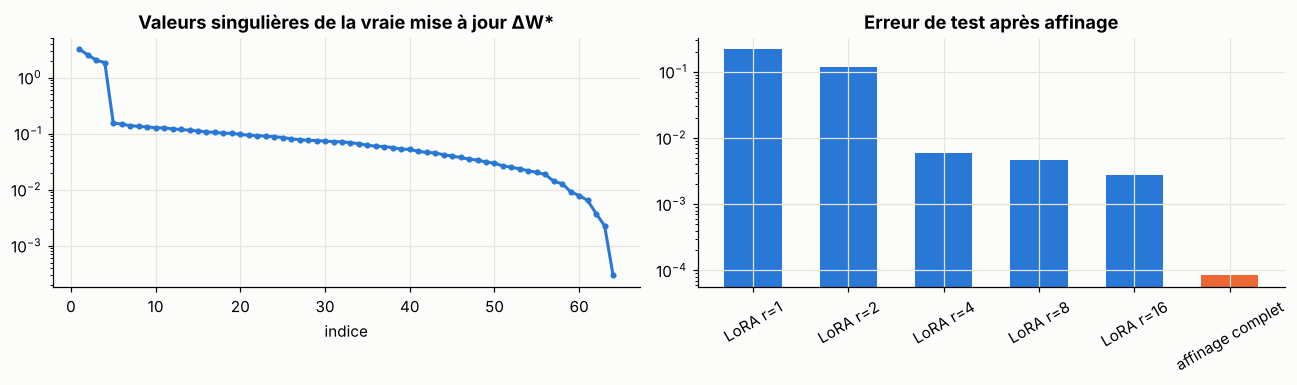

In [2]:
d_in, d_out, n = 64, 64, 2000
W0 = rng.normal(0, 1 / np.sqrt(d_in), (d_out, d_in))
U = rng.normal(size=(d_out, 4)); Vt = rng.normal(size=(4, d_in))
dW_true = 0.3 * U @ Vt / np.sqrt(d_in) + 0.01 * rng.normal(size=(d_out, d_in))      # ~rank-4 update + small noise
X = rng.normal(size=(n, d_in)); Y = X @ (W0 + dW_true).T + 0.05 * rng.normal(size=(n, d_out))
X_te = rng.normal(size=(500, d_in)); Y_te = X_te @ (W0 + dW_true).T

def finetune(rank=None, steps=1500, lr=1e-2, alpha=None):
    r = np.random.default_rng(1)
    if rank is None:                                             # full fine-tuning: learn the whole delta
        D = np.zeros_like(W0); params = [D]
        delta = lambda: D
    else:
        alpha = alpha or rank
        A = r.normal(0, 1 / np.sqrt(d_in), (rank, d_in)); B = np.zeros((d_out, rank)); params = [A, B]
        delta = lambda: (alpha / rank) * B @ A
    opt = Adam(params, lr=lr)
    for _ in range(steps):
        R = X @ (W0 + delta()).T - Y                            # residuals (n, d_out)
        G = 2 * R.T @ X / n                                      # dL/dW (d_out, d_in) for the MSE
        if rank is None:
            opt.step([G / d_out])
        else:
            s = alpha / rank
            opt.step([s * B.T @ G / d_out, s * G @ A.T / d_out])   # chain rule through W = W0 + s * B A
    test_mse = np.mean((X_te @ (W0 + delta()).T - Y_te) ** 2)
    n_trainable = sum(p.size for p in params)
    return test_mse, n_trainable

results = {"aucun affinage": (np.mean((X_te @ W0.T - Y_te) ** 2), 0)}
for rank in [1, 2, 4, 8, 16]:
    results[f"LoRA r={rank}"] = finetune(rank)
results["affinage complet"] = finetune(None)
for k, (mse, npar) in results.items():
    print(f"{k:16s} test MSE {mse:.4f} | trainable parameters {npar:6d}")

sv = np.linalg.svd(dW_true, compute_uv=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].semilogy(np.arange(1, len(sv) + 1), sv, "o-", ms=3)
axes[0].set_title("Valeurs singulières de la vraie mise à jour ΔW*"); axes[0].set_xlabel("indice")
names = list(results)[1:]
axes[1].bar(names, [results[k][0] for k in names], color=[PALETTE[0]] * 5 + [PALETTE[1]], width=0.6)
axes[1].set_yscale("log"); axes[1].set_title("Erreur de test après affinage"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Lecture** : les valeurs singulières de $\Delta W^\star$ chutent brutalement après 4 : l'essentiel de la mise à jour vit dans un sous-espace de dimension 4. LoRA de rang 4 récupère environ 98 % du gain (MSE 0.37 → 0.006) avec **8 fois moins** de paramètres entraînés ; en dessous de 4, le modèle n'a pas la capacité de représenter la mise à jour. Le petit écart restant avec l'affinage complet correspond à la composante de bruit **de rang plein** qu'on a ajoutée à $\Delta W^\star$, que seul l'affinage complet peut capturer (l'échelle log de la figure l'exagère visuellement). Pour les vrais modèles, on ne connaît pas ce rang : on le traite comme un hyperparamètre ($r\in\{4, 8, 16, 32\}$ est typique).

> ⚠️ **Nuance** : l'hypothèse de bas rang marche très bien pour adapter le **comportement** d'un modèle à une tâche, moins bien pour lui faire apprendre beaucoup de **connaissances nouvelles** (un domaine très éloigné). C'est pourquoi on fait souvent le DAPT en affinage complet, et l'affinage par tâche en LoRA.

### LoRA en PyTorch, de zéro puis avec `peft`

In [ ]:
import torch.nn as nn

class LoRALinear(nn.Module):
    """Wraps a frozen nn.Linear: y = W0 x + (alpha/r) * B(A(dropout(x)))."""

    def __init__(self, base: nn.Linear, r=8, alpha=16, dropout=0.05):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False                                   # W0 frozen
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))      # B = 0 -> starts exactly at W0
        self.scale, self.drop = alpha / r, nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * (self.drop(x) @ self.A.T @ self.B.T)

    @torch.no_grad()
    def merge(self):
        """Fold the update into W0 for zero-overhead inference."""
        self.base.weight += self.scale * self.B @ self.A
        return self.base


lin = nn.Linear(768, 768)
lora = LoRALinear(lin, r=8)
x = torch.randn(4, 768)
print("identical at init:", torch.allclose(lora(x), lin(x)))
print("trainable:", sum(p.numel() for p in lora.parameters() if p.requires_grad), "vs full:", 768 * 768 + 768)

In [ ]:
from peft import LoraConfig, get_peft_model, TaskType

model = AutoModelForTokenClassification.from_pretrained("camembert-base", num_labels=7)
print([n for n, _ in model.named_modules() if n.endswith("attention.self.query")][:2])   # find target module names
lora_cfg = LoraConfig(task_type=TaskType.TOKEN_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                      target_modules=["query", "value"])     # names depend on the architecture
peft_model = get_peft_model(model, lora_cfg)
peft_model.print_trainable_parameters()   # the classification head is kept trainable automatically for TOKEN_CLS
# peft_model is a regular nn.Module: train it with Trainer exactly as in module 7, typically with a HIGHER lr (1e-4 to 5e-4)
# after training: peft_model.save_pretrained("lora-adapter")  -> a few MB
# merged = peft_model.merge_and_unload()                      -> plain model for deployment

> 📎 **QLoRA** (Dettmers et al., 2023) : le modèle de base gelé est stocké en 4 bits, seuls les adaptateurs LoRA sont en 16 bits. Permet d'affiner un modèle de 65 milliards de paramètres sur un seul GPU de 48 Go.

## 4. L'apprentissage multi-tâche et la pondération des pertes

### 💡 Intuition

Quand plusieurs annotations portent sur les **mêmes entrées** (par exemple : le type d'une séquence, ses régions, sa famille…), un seul encodeur partagé avec **une tête par tâche** peut :
- **partager** l'information : une tâche aide les autres à apprendre de meilleures représentations (régularisation mutuelle) ;
- **coûter moins** qu'un modèle par tâche, à l'entraînement et à l'inférence ;
- mais aussi souffrir de **transfert négatif** : une tâche dominante (perte plus grande, plus de données, gradients plus forts) écrase les autres.

La perte totale est une somme pondérée $\mathcal L = \sum_i w_i\mathcal L_i$. **Tout le problème est le choix des $w_i$.** Les pertes n'ont pas la même échelle (une MSE en Å², une entropie croisée en nats…), et chercher les poids par grille coûte cher dès qu'il y a plus de deux tâches.

### 📐 La pondération par incertitude homoscédastique (Kendall, Gal & Cipolla, 2018)

Idée : modéliser chaque tâche par une vraisemblance avec un **bruit propre à la tâche** $\sigma_i$ (homoscédastique = le même pour toutes les entrées), et **apprendre** $\sigma_i$ par maximum de vraisemblance.

Pour une régression gaussienne $y_i\sim\mathcal N(f_i(x), \sigma_i^2)$ :
$$
-\log p(y_i\mid x) = \frac{1}{2\sigma_i^2}\lVert y_i - f_i(x)\rVert^2 + \log\sigma_i + \text{cste}
$$
D'où la perte multi-tâche :
$$
\mathcal L(\theta, \sigma_1,\dots,\sigma_K) = \sum_{i=1}^K \frac{1}{2\sigma_i^2}\mathcal L_i(\theta) + \log\sigma_i
$$
- une tâche **bruitée / difficile** (grand $\sigma_i$) est automatiquement **moins pondérée** ;
- le terme $\log\sigma_i$ empêche la solution triviale $\sigma_i\to\infty$ ;
- à $\theta$ fixé, l'optimum est $\sigma_i^2 = \mathcal L_i$ : chaque tâche est pondérée par l'**inverse de sa perte courante** ;
- pour une classification (softmax avec température $\sigma^2$), Kendall et al. obtiennent l'approximation $\frac{1}{\sigma_i^2}\mathcal L_i + \log\sigma_i$.

En pratique, on paramètre $s_i = \log\sigma_i^2$ (stable numériquement, non contraint) :
$$
\mathcal L = \sum_i \tfrac12 e^{-s_i}\mathcal L_i + \tfrac12 s_i\qquad\Longrightarrow\qquad \frac{\partial\mathcal L}{\partial s_i} = \tfrac12\left(1 - e^{-s_i}\mathcal L_i\right)
$$

### 📊 Démonstration

Deux tâches de régression sur les mêmes entrées, un encodeur partagé (une couche tanh), deux têtes linéaires. La tâche 1 est **précise** (bruit $\sigma_1 = 0.1$), la tâche 2 est **très bruitée** et d'amplitude plus grande ($\sigma_2 = 2$). Avec des poids égaux, la tâche 2 domine la perte et le gradient.

In [3]:
n, d_x, d_h = 3000, 6, 16
Xm = rng.normal(size=(n, d_x))
f1 = np.sin(Xm[:, 0]) + 0.5 * Xm[:, 1] * Xm[:, 2]          # task 1 signal
f2 = 3 * np.cos(Xm[:, 3]) + 2 * Xm[:, 4]                    # task 2 signal (bigger scale)
true_sigma = np.array([0.1, 2.0])
Y1 = f1 + true_sigma[0] * rng.normal(size=n); Y2 = f2 + true_sigma[1] * rng.normal(size=n)
tr, te = slice(0, 2000), slice(2000, None)


def train_mtl(mode, steps=4000, lr=5e-3, seed=0):
    r = np.random.default_rng(seed)
    W = r.normal(0, 1 / np.sqrt(d_x), (d_x, d_h)); b = np.zeros(d_h)
    v1 = r.normal(0, 0.1, d_h); v2 = r.normal(0, 0.1, d_h); c = np.zeros(2)
    s = np.zeros(2)                                          # log sigma^2, learned only in "uncertainty" mode
    params = [W, b, v1, v2, c, s]
    opt = Adam(params, lr=lr)
    hist = []
    X_, y1, y2 = Xm[tr], Y1[tr], Y2[tr]
    for it in range(steps):
        H = np.tanh(X_ @ W + b)
        e1 = H @ v1 + c[0] - y1; e2 = H @ v2 + c[1] - y2
        L1, L2 = np.mean(e1**2), np.mean(e2**2)
        if mode == "equal":
            w = np.array([1.0, 1.0]); g_s = np.zeros(2)
        else:
            w = np.exp(-s)                                   # 1/sigma^2 (the 1/2 factor is common to both terms)
            g_s = 0.5 * (1 - np.exp(-s) * np.array([L1, L2]))
        # backprop through both heads and the shared encoder; total = 0.5*w1*L1 + 0.5*w2*L2 (+ 0.5*s)
        dy1 = w[0] * e1 / len(y1); dy2 = w[1] * e2 / len(y2)          # d(0.5*w*mean(e^2))/de = w*e/n
        g_v1, g_v2 = H.T @ dy1, H.T @ dy2
        g_c = np.array([dy1.sum(), dy2.sum()])
        dH = np.outer(dy1, v1) + np.outer(dy2, v2)
        dZ = dH * (1 - H**2)
        opt.step([X_.T @ dZ, dZ.sum(0), g_v1, g_v2, g_c, g_s])
        if it % 50 == 0:
            hist.append((it, np.sqrt(np.exp(s)), L1, L2))
    He = np.tanh(Xm[te] @ W + b)
    rmse1 = np.sqrt(np.mean((He @ v1 + c[0] - f1[te]) ** 2))         # error vs the NOISE-FREE signal
    rmse2 = np.sqrt(np.mean((He @ v2 + c[1] - f2[te]) ** 2))
    return rmse1, rmse2, hist

res = {}
for mode in ["equal", "uncertainty"]:
    runs = [train_mtl(mode, seed=sd) for sd in range(3)]
    res[mode] = runs
    r1 = np.array([x[0] for x in runs]); r2 = np.array([x[1] for x in runs])
    print(f"{mode:12s} | task 1 RMSE {r1.mean():.3f} ± {r1.std():.3f} | task 2 RMSE {r2.mean():.3f} ± {r2.std():.3f}  (3 seeds)")

equal        | task 1 RMSE 0.152 ± 0.024 | task 2 RMSE 0.599 ± 0.012  (3 seeds)
uncertainty  | task 1 RMSE 0.045 ± 0.004 | task 2 RMSE 0.465 ± 0.016  (3 seeds)


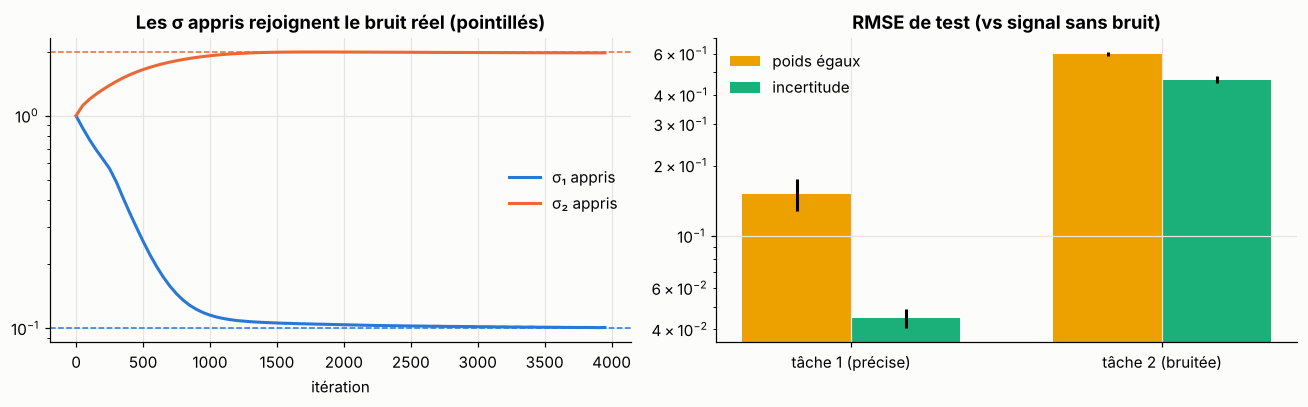

In [4]:
h = np.array([(it, sg[0], sg[1], l1, l2) for it, sg, l1, l2 in res["uncertainty"][0][2]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h[:, 0], h[:, 1], color=PALETTE[0], label="σ₁ appris")
axes[0].plot(h[:, 0], h[:, 2], color=PALETTE[1], label="σ₂ appris")
for sv_, c in zip(true_sigma, PALETTE[:2]):
    axes[0].axhline(sv_, color=c, ls="--", lw=1)
axes[0].set_yscale("log"); axes[0].set_xlabel("itération"); axes[0].set_title("Les σ appris rejoignent le bruit réel (pointillés)"); axes[0].legend()
labels_ = ["tâche 1 (précise)", "tâche 2 (bruitée)"]
x_ = np.arange(2)
for k, (mode, c) in enumerate(zip(["equal", "uncertainty"], [PALETTE[3], PALETTE[2]])):
    vals = np.array([[x[0], x[1]] for x in res[mode]])
    axes[1].bar(x_ + (k - 0.5) * 0.35, vals.mean(0), yerr=vals.std(0), width=0.35, color=c, label={"equal": "poids égaux", "uncertainty": "incertitude"}[mode])
axes[1].set_xticks(x_); axes[1].set_xticklabels(labels_); axes[1].set_yscale("log")
axes[1].set_title("RMSE de test (vs signal sans bruit)"); axes[1].legend()
plt.tight_layout(); plt.show()

**Lecture** : avec la pondération par incertitude, les $\sigma_i$ appris convergent vers le vrai niveau de bruit de chaque tâche, sans qu'on le leur ait donné. La tâche précise reçoit alors un poids $1/\sigma_1^2$ environ 400 fois plus grand que la tâche bruitée, et son erreur de test est divisée par ~3. Ici, la tâche bruitée s'améliore aussi : moins pondérée, elle sur-ajuste moins son propre bruit. Avec des poids égaux, le réseau consacre sa capacité à réduire la grosse perte de la tâche 2, dont l'essentiel est du bruit irréductible.

> ⚠️ **Lecture critique, en relecteur exigeant** :
> - La méthode suppose que $\mathcal L_i$ reflète un **bruit** propre à la tâche. Une tâche à forte perte parce que **le modèle est mauvais** dessus (et non parce qu'elle est bruitée) sera elle aussi sous-pondérée, ce qui peut être l'inverse de ce qu'on souhaite.
> - Avec des tâches de **classification**, la forme exacte du terme de régularisation est une approximation ; des variantes existent (par exemple $\log(1+\sigma_i^2)$ pour garder un terme positif, Liebel & Körner, 2018).
> - Plusieurs études ont trouvé que des poids bien choisis à la main, ou même égaux après normalisation des pertes, font souvent jeu égal avec les méthodes adaptatives (Xin et al., 2022, « Do current multi-task optimization methods… »). **Toujours comparer** à la pondération égale et à un modèle mono-tâche, avec plusieurs graines.
> - Alternatives à connaître : **GradNorm** (équilibre les normes de gradient par tâche), **PCGrad** (projette les gradients conflictuels), **DWA** (pondère selon la vitesse de décroissance des pertes).

### Le multi-tâche en PyTorch, avec des étiquettes manquantes

Dans un vrai projet, tous les exemples n'ont pas toutes les annotations. On masque simplement les pertes : `-100` pour l'étiquetage de tokens, et un masque par exemple pour les tâches de séquence.

In [ ]:
import torch.nn.functional as F
from transformers import AutoModel


class UncertaintyWeighting(nn.Module):
    """L = sum_i 0.5 * exp(-s_i) * L_i + 0.5 * s_i  with s_i = log sigma_i^2 learned (Kendall et al., 2018)."""

    def __init__(self, task_names):
        super().__init__()
        self.task_names = list(task_names)
        self.log_vars = nn.Parameter(torch.zeros(len(self.task_names)))

    def forward(self, losses: dict):
        total = 0.0
        for i, name in enumerate(self.task_names):
            if name in losses and losses[name] is not None:             # task absent from this batch -> skipped
                total = total + 0.5 * torch.exp(-self.log_vars[i]) * losses[name] + 0.5 * self.log_vars[i]
        return total

    def sigmas(self):
        return {n: float(torch.exp(0.5 * s)) for n, s in zip(self.task_names, self.log_vars)}


class MultiTaskModel(nn.Module):
    """Shared Transformer encoder + one token-level head + one sequence-level head."""

    def __init__(self, backbone="camembert-base", n_token_labels=7, n_seq_labels=4, dropout=0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(backbone)
        d = self.encoder.config.hidden_size
        self.drop = nn.Dropout(dropout)
        self.token_head = nn.Linear(d, n_token_labels)           # e.g. region labels (BIO)
        self.seq_head = nn.Sequential(nn.Linear(d, d), nn.Tanh(), nn.Linear(d, n_seq_labels))   # e.g. type
        self.weighting = UncertaintyWeighting(["token", "sequence"])

    def forward(self, input_ids, attention_mask, token_labels=None, seq_labels=None):
        h = self.drop(self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state)  # (B, T, d)
        token_logits = self.token_head(h)
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        seq_logits = self.seq_head((h * m).sum(1) / m.sum(1))   # masked mean pooling
        losses = {}
        if token_labels is not None and (token_labels != -100).any():
            losses["token"] = F.cross_entropy(token_logits.flatten(0, 1), token_labels.flatten(), ignore_index=-100)
        if seq_labels is not None and (seq_labels != -100).any():
            losses["sequence"] = F.cross_entropy(seq_logits, seq_labels, ignore_index=-100)   # -100 = missing label
        loss = self.weighting(losses) if losses else None
        return {"loss": loss, "losses": losses, "token_logits": token_logits, "seq_logits": seq_logits}


mtl = MultiTaskModel()
# Optimizer: the log-variances usually get a larger lr and NO weight decay
opt = torch.optim.AdamW([
    {"params": mtl.encoder.parameters(), "lr": 3e-5, "weight_decay": 0.01},
    {"params": list(mtl.token_head.parameters()) + list(mtl.seq_head.parameters()), "lr": 1e-3, "weight_decay": 0.01},
    {"params": mtl.weighting.parameters(), "lr": 1e-2, "weight_decay": 0.0},
])
# In the training loop: out = mtl(**batch); out["loss"].backward(); ...
# Log out["losses"] per task AND mtl.weighting.sigmas() at every evaluation: they are part of the results.

> 💡 **Échantillonnage des tâches** : si les tâches viennent de jeux de données différents (tailles différentes), on alterne des batchs mono-tâche. Tirer la tâche $i$ avec une probabilité $\propto n_i^{1/T}$ ($T = 1$ : proportionnel à la taille ; $T\to\infty$ : uniforme ; $T\approx 2$–$5$ est un bon compromis, utilisé dans T5 et les modèles multilingues).

## 5. Évaluer sans se mentir (1) : la fuite par similarité

### 💡 Le problème

Un split **aléatoire** suppose que les exemples sont indépendants. C'est faux dès que des exemples sont des **quasi-doublons** : paraphrases, versions successives d'un même document, ou, en biologie, **séquences homologues** (même famille, quelques mutations). Un modèle peut alors obtenir un score excellent en **mémorisant** les familles vues à l'entraînement, sans avoir appris la règle. Le score mesure l'interpolation, pas la généralisation à des données vraiment nouvelles.

### 📊 Démonstration

On génère 60 familles de séquences : chaque famille a une séquence ancestrale, et ses membres en dérivent par 10 % de mutations. L'étiquette suit une **vraie règle** : la proportion de résidus hydrophobes dans une région (les 20 premières positions) dépasse un seuil. Les familles ont des compositions variées. On compare deux modèles :
- **le plus proche voisin** en distance de Hamming (il peut mémoriser les familles) ;
- **une régression logistique sur la composition globale** (20 fréquences d'acides aminés) : elle ne voit pas la région, mais capte la tendance générale qui la détermine en partie ;

et deux protocoles : split aléatoire, et split **par famille** (aucune famille du test n'est vue à l'entraînement).

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

AA = np.array(list("ACDEFGHIKLMNPQRSTVWY"))
HYDRO = np.isin(AA, list("AILMFVW"))
L_seq, n_fam, per_fam = 60, 60, 25
r = np.random.default_rng(3)
seqs, fams = [], []
for f in range(n_fam):
    bias = r.uniform(0.15, 0.6)                                       # family-specific hydrophobic fraction
    p_aa = np.where(HYDRO, bias / HYDRO.sum(), (1 - bias) / (~HYDRO).sum())
    ancestor = r.choice(20, L_seq, p=p_aa)
    for _ in range(per_fam):
        s = ancestor.copy()
        mut = r.random(L_seq) < 0.10
        s[mut] = r.choice(20, mut.sum(), p=p_aa)                      # mutations keep the family's composition bias
        seqs.append(s); fams.append(f)
seqs, fams = np.array(seqs), np.array(fams)
region_hydro = HYDRO[seqs[:, :20]].mean(1)                              # hydrophobic fraction in a 20-residue region
labels = (region_hydro > np.median(region_hydro)).astype(int)          # the "true rule"

onehot = np.eye(20)[seqs].reshape(len(seqs), -1)                         # for Hamming-like kNN
composition = np.eye(20)[seqs].mean(1)                                   # 20 amino-acid frequencies

def evaluate(splitter, groups=None, n_rep=10):
    out = {"kNN (mémorise)": [], "LogReg composition": []}
    for tr_i, te_i in splitter.split(seqs, labels, groups):
        knn = KNeighborsClassifier(n_neighbors=1, metric="hamming").fit(seqs[tr_i], labels[tr_i])
        out["kNN (mémorise)"].append(knn.score(seqs[te_i], labels[te_i]))
        lr_ = LogisticRegression(C=10, max_iter=2000).fit(composition[tr_i], labels[tr_i])
        out["LogReg composition"].append(lr_.score(composition[te_i], labels[te_i]))
    return {k: (np.mean(v), np.std(v)) for k, v in out.items()}

random_split = evaluate(ShuffleSplit(n_splits=10, test_size=0.2, random_state=0))
family_split = evaluate(GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=0), groups=fams)
for name in random_split:
    print(f"{name:28s} random split {random_split[name][0]:.3f} ± {random_split[name][1]:.3f} | "
          f"family split {family_split[name][0]:.3f} ± {family_split[name][1]:.3f}")

kNN (mémorise)               random split 0.904 ± 0.021 | family split 0.631 ± 0.061
LogReg composition           random split 0.860 ± 0.018 | family split 0.810 ± 0.042


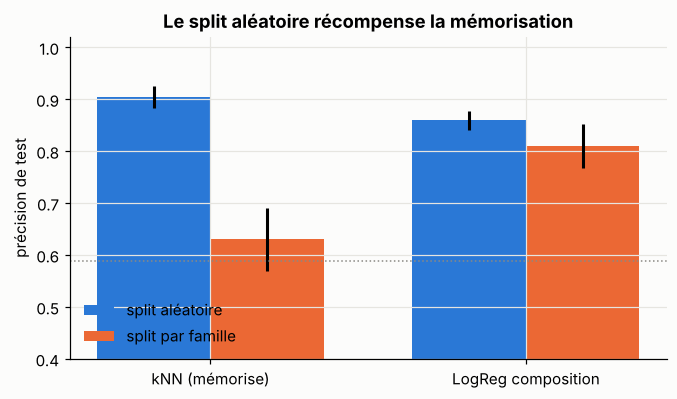

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(random_split)
xk = np.arange(len(names))
ax.bar(xk - 0.18, [random_split[k][0] for k in names], 0.36, yerr=[random_split[k][1] for k in names], color=PALETTE[0], label="split aléatoire")
ax.bar(xk + 0.18, [family_split[k][0] for k in names], 0.36, yerr=[family_split[k][1] for k in names], color=PALETTE[1], label="split par famille")
ax.set_xticks(xk); ax.set_xticklabels(names); ax.set_ylim(0.4, 1.02); ax.set_ylabel("précision de test")
ax.axhline(max(labels.mean(), 1 - labels.mean()), color="#8a8984", ls=":", lw=1)
ax.set_title("Le split aléatoire récompense la mémorisation"); ax.legend(loc="lower left")
plt.show()

**Lecture** : sur le split aléatoire, le plus proche voisin semble **le meilleur** modèle : chaque séquence de test a des « sœurs » de la même famille à l'entraînement, et il lui suffit de recopier leur étiquette. Sur le split par famille, il s'effondre vers le hasard, alors que la régression logistique, qui a appris une tendance réellement liée à la règle, perd peu. **Le classement des deux modèles s'inverse selon le protocole.** Un article qui ne rapporterait que le split aléatoire conclurait l'inverse de ce qui se passera sur de nouvelles familles.

**Bonnes pratiques** :
- **Texte** : dédupliquer (hachage exact, puis quasi-doublons par MinHash / similarité d'embeddings) ; séparer par document, auteur, source ou date (split temporel) selon l'usage visé.
- **Séquences biologiques** : regrouper par similarité (MMseqs2, CD-HIT) à un seuil d'identité (souvent 30 %, 50 % ou 90 %, à justifier), puis splitter **par cluster** ; rapporter les scores **en fonction de l'identité maximale** au jeu d'entraînement.
- **Pré-entraînement** : vérifier que les exemples de test ne sont pas dans le corpus de pré-entraînement ou de DAPT/TAPT.

## 6. Évaluer sans se mentir (2) : incertitude et comparaison de modèles

### 📐 Intervalles de confiance par bootstrap

Un score sur un jeu de test fini est une **estimation**. Le bootstrap estime sa variabilité : on rééchantillonne le jeu de test **avec remise** $B$ fois, on recalcule la métrique à chaque fois, et on prend les percentiles 2,5 % et 97,5 %. Valable pour n'importe quelle métrique (F1 par entité compris).

### 📐 Comparer deux modèles : le bootstrap **apparié**

Pour comparer A et B **sur le même jeu de test**, on rééchantillonne les **mêmes** exemples pour les deux modèles et on regarde la distribution de la **différence**. C'est bien plus puissant que de comparer deux intervalles séparés, car la difficulté propre à chaque exemple s'annule. (Test classique équivalent pour l'accuracy : McNemar.)

accuracy A = 0.858  95% CI [0.83  0.885]
accuracy B = 0.872  95% CI [0.845 0.898]
B - A      = +0.013  paired 95% CI [-0.002  0.03 ] | P(B <= A) ≈ 0.057
           (unpaired CI of the difference, for comparison: [-0.025  0.053] -> much wider)
McNemar: B right & A wrong = 16, A right & B wrong = 8, p = 0.1516


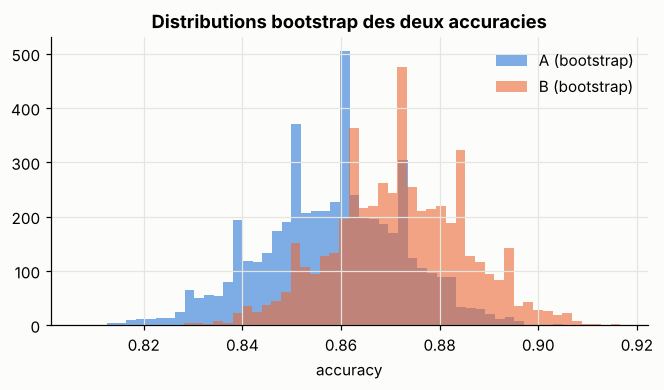

In [7]:
n_test = 600
difficulty = rng.beta(2, 5, n_test)                                     # some examples are hard for everyone
correct_A = rng.random(n_test) > difficulty * 0.55
correct_B = np.where(rng.random(n_test) < 0.85, correct_A, rng.random(n_test) > difficulty * 0.3)  # B ~ A, slightly better

def bootstrap(metric_fn, *arrays, B=5000, seed=0):
    r = np.random.default_rng(seed)
    n = len(arrays[0])
    idx = r.integers(0, n, (B, n))
    return np.array([metric_fn(*(a[i] for a in arrays)) for i in idx])

acc = lambda c: c.mean()
bs_A, bs_B = bootstrap(acc, correct_A), bootstrap(acc, correct_B, seed=1)
bs_diff = bootstrap(lambda a, b: b.mean() - a.mean(), correct_A, correct_B)
ci = lambda v: np.percentile(v, [2.5, 97.5])
print(f"accuracy A = {correct_A.mean():.3f}  95% CI {ci(bs_A).round(3)}")
print(f"accuracy B = {correct_B.mean():.3f}  95% CI {ci(bs_B).round(3)}")
print(f"B - A      = {correct_B.mean() - correct_A.mean():+.3f}  paired 95% CI {ci(bs_diff).round(3)} | P(B <= A) ≈ {(bs_diff <= 0).mean():.3f}")
print(f"           (unpaired CI of the difference, for comparison: {ci(bs_B - bs_A).round(3)} -> much wider)")

# McNemar (exact binomial on discordant pairs)
from scipy.stats import binomtest
b01 = int(np.sum(~correct_A & correct_B)); b10 = int(np.sum(correct_A & ~correct_B))
print(f"McNemar: B right & A wrong = {b01}, A right & B wrong = {b10}, p = {binomtest(b01, b01 + b10, 0.5).pvalue:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(bs_A, bins=50, alpha=0.6, color=PALETTE[0], label="A (bootstrap)")
ax.hist(bs_B, bins=50, alpha=0.6, color=PALETTE[1], label="B (bootstrap)")
ax.set_title("Distributions bootstrap des deux accuracies"); ax.set_xlabel("accuracy"); ax.legend()
plt.show()

**Lecture** : B fait mieux de ~1,5 point. L'IC **apparié** de la différence est environ trois fois plus étroit que l'IC non apparié, car la difficulté propre à chaque exemple s'annule. Il contient pourtant encore 0, et McNemar n'est pas significatif : **sur ce jeu de test, on ne peut pas affirmer que B est meilleur**. Pour détecter de façon fiable un écart d'un point, il faudrait un jeu de test plus grand (la largeur de l'IC décroît en $1/\sqrt{n}$) ou un écart plus grand.

**La leçon** : deux intervalles qui se chevauchent ne prouvent **pas** que les modèles sont équivalents, et une différence de score ne prouve pas qu'un modèle est meilleur ; c'est la distribution de la **différence appariée** qui permet de trancher, ou de dire honnêtement qu'on ne peut pas trancher. Inversement, une différence significative sur **une seule graine** d'entraînement ne prouve rien sur la **méthode** : il faut aussi la variance entre graines (module 7, exercice 3).

### Les deux sources de variance

| Source | Comment l'estimer | Ce qu'elle dit |
|---|---|---|
| Échantillonnage du **jeu de test** | bootstrap / IC | « ce modèle-là, sur une autre population de test » |
| **Entraînement** (graine, ordre des données, initialisation de la tête) | 3–10 graines, moyenne ± écart-type | « cette méthode, ré-entraînée » |

Pour une comparaison de méthodes publiable : plusieurs graines **et** des IC, et si possible un test apparié sur les prédictions moyennées ou un test sur les scores par graine.

## 7. Évaluer sans se mentir (3) : la calibration

### 💡 Intuition

Un modèle est **calibré** si, parmi tous les exemples auxquels il attribue une confiance de 80 %, environ 80 % sont corrects. Les réseaux modernes affinés sont souvent **sur-confiants** (Guo et al., 2017). Pour un outil d'annotation, c'est crucial : la confiance sert à décider quoi vérifier manuellement.

### 📐 Mesurer : diagramme de fiabilité et ECE

On répartit les prédictions en $M$ intervalles de confiance $B_m$, et on compare précision et confiance moyennes dans chacun :
$$
\mathrm{ECE} = \sum_{m=1}^M \frac{|B_m|}{n}\,\big|\mathrm{acc}(B_m) - \mathrm{conf}(B_m)\big|
$$

### 📐 Corriger : le *temperature scaling*

On divise tous les logits par un scalaire $T > 0$ appris sur le jeu de **validation** en minimisant la NLL. Les prédictions (argmax) sont **inchangées**, seules les confiances sont ajustées. Un seul paramètre : très peu de risque de sur-apprentissage.

fitted temperature T = 3.04 (the simulation used a factor 3)
avant                      accuracy 0.553 | NLL 1.718 | ECE 0.267
après temperature scaling  accuracy 0.553 | NLL 1.127 | ECE 0.007


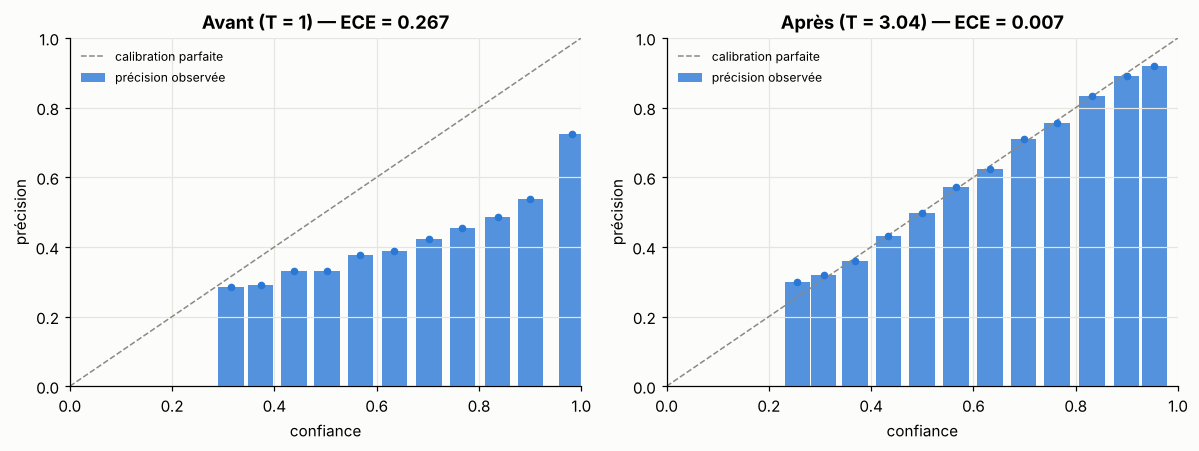

In [8]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True); e = np.exp(z); return e / e.sum(axis=axis, keepdims=True)

# Simulate an over-confident 5-class classifier: logits = 3 x "calibrated" logits
K_cls, n_val, n_te = 5, 2000, 4000
def simulate(n, seed):
    r = np.random.default_rng(seed)
    true_logits = r.normal(0, 1.2, (n, K_cls)); true_logits[np.arange(n), r.integers(0, K_cls, n)] += 1.5
    y = np.array([r.choice(K_cls, p=p) for p in softmax(true_logits)])      # labels drawn from calibrated probs
    return 3.0 * true_logits, y                                               # the model is over-confident
logits_val, y_val = simulate(n_val, 1); logits_te, y_te = simulate(n_te, 2)

def ece(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    e, accs, confs, counts = 0.0, [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            a, c = (pred[m] == y[m]).mean(), conf[m].mean()
            e += m.mean() * abs(a - c); accs.append(a); confs.append(c); counts.append(m.sum())
    return e, np.array(confs), np.array(accs), np.array(counts)

nll = lambda logits, y, T: -np.log(softmax(logits / T)[np.arange(len(y)), y] + 1e-12).mean()
Ts = np.linspace(0.5, 6, 200)
T_best = Ts[np.argmin([nll(logits_val, y_val, T) for T in Ts])]          # fitted on VALIDATION only
print(f"fitted temperature T = {T_best:.2f} (the simulation used a factor 3)")
for name, T in [("avant", 1.0), ("après temperature scaling", T_best)]:
    p = softmax(logits_te / T)
    print(f"{name:26s} accuracy {(p.argmax(1) == y_te).mean():.3f} | NLL {nll(logits_te, y_te, T):.3f} | ECE {ece(p, y_te)[0]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, T) in zip(axes, [("Avant (T = 1)", 1.0), (f"Après (T = {T_best:.2f})", T_best)]):
    e, confs, accs, counts = ece(softmax(logits_te / T), y_te)
    ax.plot([0, 1], [0, 1], color="#8a8984", ls="--", lw=1, label="calibration parfaite")
    ax.bar(confs, accs, width=0.05, color=PALETTE[0], alpha=0.8, label="précision observée")
    ax.plot(confs, accs, "o", color=PALETTE[0], ms=4)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("confiance"); ax.set_ylabel("précision")
    ax.set_title(f"{name} — ECE = {e:.3f}"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

En PyTorch, le temperature scaling se fait en optimisant un unique paramètre $\log T$ sur les logits de validation (avec `torch.optim.LBFGS` par exemple). Pour l'étiquetage de tokens, on calibre au niveau des tokens ; pour des décisions par **segment**, il faut aussi vérifier la calibration de la confiance agrégée par segment.

## 8. Check-list d'un protocole expérimental publiable

**Données**
- [ ] Splits définis **avant** toute expérience, figés et publiés (identifiants).
- [ ] Split par cluster / famille / source / date, seuil de similarité justifié ; scores rapportés en fonction de la distance au jeu d'entraînement.
- [ ] Déduplication entre corpus de pré-entraînement (DAPT/TAPT) et jeux de validation/test.
- [ ] Statistiques des jeux : tailles, déséquilibre des classes, longueurs.

**Modèles et baselines**
- [ ] Baselines simples **bien réglées** (règles, n-grammes + régression logistique, kNN par similarité, outil existant de référence).
- [ ] Ablations : base / +DAPT / +TAPT / mono-tâche / multi-tâche (poids égaux vs incertitude) / affinage complet vs LoRA.
- [ ] Même budget de réglage d'hyperparamètres pour chaque méthode comparée (sinon la comparaison est biaisée).

**Évaluation**
- [ ] Métriques adaptées : F1 par entité/segment, tolérance aux frontières si pertinent, macro-F1 pour les classes rares.
- [ ] 3 à 10 graines, moyenne ± écart-type ; IC bootstrap ; test apparié pour les comparaisons principales.
- [ ] Calibration (ECE, diagrammes de fiabilité) si les scores de confiance sont utilisés.
- [ ] Analyse d'erreurs qualitative : catégories d'erreurs, exemples, cas limites.
- [ ] Le jeu de test n'est consulté **qu'une fois**, à la fin.

**Reproductibilité**
- [ ] Code, configurations, graines, versions des librairies, checkpoints (ou adaptateurs LoRA) publiés.
- [ ] Coût de calcul rapporté (GPU-heures).

## 9. Récapitulatif

| Notion | À retenir |
|---|---|
| DAPT / TAPT | continuer le MLM/CLM sur le domaine puis sur les textes de la tâche ; surveiller l'oubli |
| LoRA | $W_0 + \frac{\alpha}{r}BA$, $B=0$ à l'init ; ~0,1–1 % des paramètres ; fusionnable |
| Multi-tâche | encodeur partagé + têtes ; risque de transfert négatif ; étiquettes manquantes masquées |
| Incertitude homoscédastique | $\sum_i \frac12 e^{-s_i}\mathcal L_i + \frac12 s_i$ ; $\sigma_i^2\to\mathcal L_i$ ; à comparer aux poids égaux |
| Fuite par similarité | split aléatoire = mémorisation récompensée ; splitter par cluster |
| Incertitude | bootstrap (test) + graines (entraînement) ; comparaisons **appariées** |
| Calibration | ECE, diagrammes de fiabilité ; temperature scaling sur la validation |

### 🏋️ Exercices

1. **LoRA et données.** Dans la démonstration LoRA, réduis $n$ à 100 exemples. L'affinage complet (4 096 paramètres) sur-apprend-il plus que LoRA r = 4 (512 paramètres) ? Que dit cela de LoRA comme **régularisation** ?
2. **Incertitude défavorable.** Modifie la démonstration multi-tâche pour que la tâche 2 soit **non bruitée mais difficile** (une fonction très non linéaire que l'encodeur à 16 neurones apprend mal). Que fait la pondération par incertitude ? Est-ce souhaitable ?
3. **Courbe identité / performance.** Dans la démonstration de fuite, calcule pour chaque séquence de test son identité maximale au jeu d'entraînement, puis trace la précision des deux modèles par tranche d'identité.
4. **Calibration par classe.** Simule un modèle sur-confiant pour une classe seulement. Le temperature scaling (un seul $T$) suffit-il ? Implémente le *vector scaling* (un $T$ par classe) et compare l'ECE par classe.
5. **Protocole.** Écris, pour ton propre projet, la section « Méthodes – évaluation » en suivant la check-list de la section 8 : splits, baselines, ablations, métriques, tests statistiques.

<details><summary>Indications</summary>

1. Avec peu de données, le rang faible contraint la solution : LoRA généralise souvent mieux que l'affinage complet. C'est un argument pour LoRA en régime de données rares, à vérifier empiriquement.
2. La tâche difficile sera sous-pondérée (grande perte = « grand bruit » pour la méthode), ce qui aggrave son sous-apprentissage. La méthode ne distingue pas bruit aléatoire et erreur de modélisation.
3. Le kNN est excellent à haute identité et s'effondre à basse identité ; le modèle « règle » est presque plat. C'est exactement la figure attendue par un relecteur pour un outil d'annotation de séquences.
</details>

**➡️ Module bonus : les modèles de langage de protéines** (ESM-2, tokenisation par acide aminé, MLM sur des séquences, embeddings de résidus, étiquetage de régions par token, et comment tout ce cours s'y transpose).